# TD6 — Du variogramme à la prédiction spatiale
*Auteurs: Guillaume Caumon et Oumayma Razik*

L'objectif de ce notebook est de couvrir l'ensemble de la chaine de prévision spatiale:
calcul et modélisation du variogramme, puis prédictions spatiales.

On s'appuie pour cela sur un ensemble de 274 points dans le plan.
Ces points correspondent à des échantillons sur l'image du [notebook précédent](02_variogramme2D.ipynb).



## 1. Chargement des données

Lecture du fichier `points_2d.csv` (274 points 2D) et créaltion du répertoire pour stocker les résultats. Nous allons aussi charger la grille à partir de laquelle ces points ont été extraits.

In [66]:
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import gstlearn as gl
import gstlearn.plot as gp
from sklearn.externals.array_api_extra import nunique

sys.path.append(os.path.abspath(os.path.join("..")))
import geostat_utils as gsutils

results = gsutils.ResultsDir("TD6_outputs_vario2D")

data_2d = pd.read_csv('../data/points_2d.csv', sep=';')
display(data_2d)

image_2D = pd.read_csv('../data/image_2D_grille.csv')
nx_map, ny_map = 100, 100
grid_2D = image_2D['Values'].to_numpy().reshape(ny_map, nx_map)

print(data_2d.to_numpy().shape)

,X,Y,Values
0,3.89860,93.60578,1.101290
1,8.88960,94.60398,-0.226447
2,8.55686,89.44660,0.625209
3,5.22952,89.11386,0.655050
4,7.72504,86.61836,0.488875
...,...,...,...
269,75.18338,62.59766,-0.371133
270,60.98078,70.60938,-0.555290
271,55.51824,62.41558,-0.619456
272,60.25244,58.40972,-0.424637


(274, 3)


## 2. Visualisation des données

Commençons par afficher ces points dans l'espace, ainsi que l'image de référence en transparence.

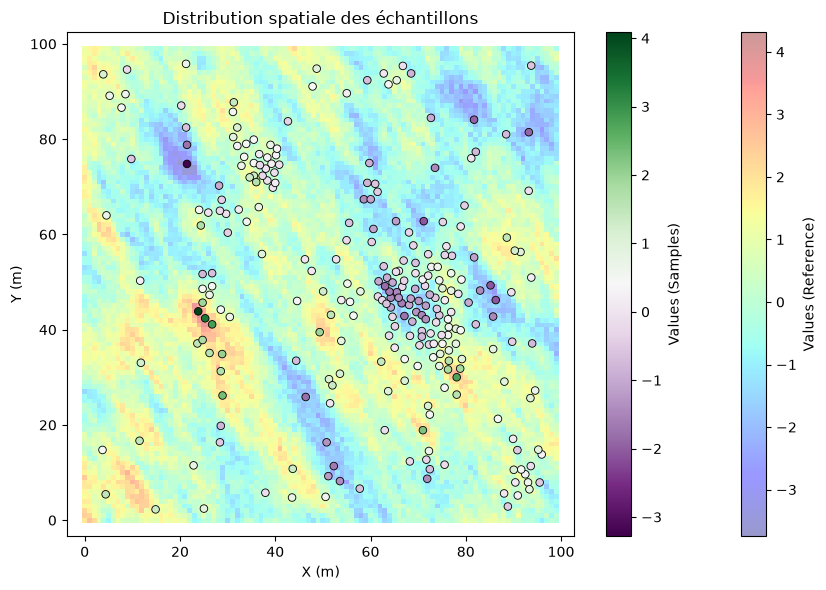

In [47]:
plt.figure(figsize=(8.8, 6))
plt.imshow(grid_image, cmap='jet', origin='lower', alpha = 0.4)
plt.colorbar(label='Values (Reference)')

plt.scatter(data_2d['X'], data_2d['Y'],
            c=data_2d['Values'],
            cmap='PRGn', s=30,
            edgecolor='k', linewidth=0.6)
plt.colorbar(label='Values (Samples)')
plt.xlabel('X (m)')
plt.ylabel('Y (m)')
plt.title('Distribution spatiale des échantillons')
plt.axis('equal')
plt.tight_layout()
plt.show()

Affichons maintenant l'histogramme

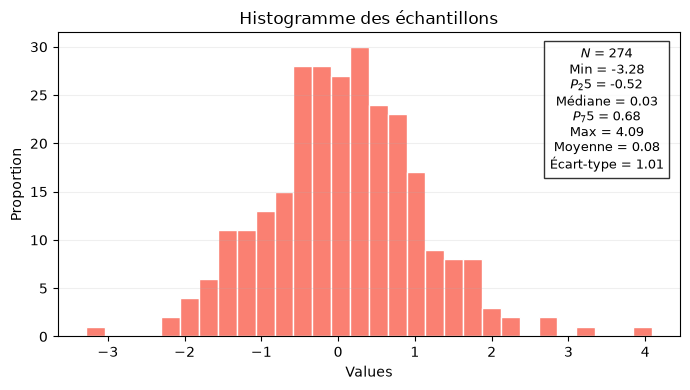

In [73]:
plt.figure(figsize=(7, 4))
plt.hist(data_2d['Values'], bins=30, color='salmon', edgecolor='white')
plt.title("Histogramme des échantillons")
plt.xlabel("Values")
plt.ylabel("Proportion")
plt.grid(axis='y', alpha=0.2)

values = data_2d['Values']
text_stats = (
        f"$N$ = {len(values)}\n"
        f"Min = {np.min(values):.2f}\n"
        f"$P_{25}$ = {np.percentile(values, 25):.2f}\n"
        f"Médiane = {np.median(values):.2f}\n"
        f"$P_{75}$ = {np.percentile(values, 75):.2f}\n"
        f"Max = {np.max(values):.2f}\n"
        f"Moyenne = {np.mean(values):.2f}\n"
        f"Écart-type = {np.std(values, ddof=1):.2f}"
    )
plt.text(3.5, 30,
    text_stats,
    fontsize=9,
    bbox=dict(facecolor='white', edgecolor='black', alpha=0.8),
    verticalalignment='top',
    horizontalalignment='center',
)

plt.tight_layout()
plt.show()

## 3. Calcul du variogramme empirique

Commençons par créer la base de données pour gsltearn.

In [74]:
gl.defineDefaultSpace(gl.ESpaceType.RN, 2)
db = gl.Db.createFromSamples(
    len(data_2d),
    tab=data_2d.to_numpy().flatten(),
    names=["X", "Y", "Values"],
    locatorNames=["x1", "x2", "z1"]
)
print(db)


Data Base Characteristics

Data Base Summary
-----------------
File is organized as a set of isolated points
Space dimension              = 2
Number of Columns            = 4
Total number of samples      = 274

Variables
---------
Column = 0 - Name = rank - Locator = NA
Column = 1 - Name = X - Locator = x1
Column = 2 - Name = Y - Locator = x2
Column = 3 - Name = Values - Locator = z1



Définition des paramètres et calcul du variogramme en 2D. Par défaut, on va le calculer dans 4 directions, mais vous pouvez aussi ajouter les deux directions préférentielles de votre choix. (NB: attention aux conventions: l'azimut est calculé en partant du nord dans le sens horaire, mais la convention d'orientation dans gstlearn est trigonométrique: 0 pour le vecteur (1 0), 90 pour le vecteur (0 1))

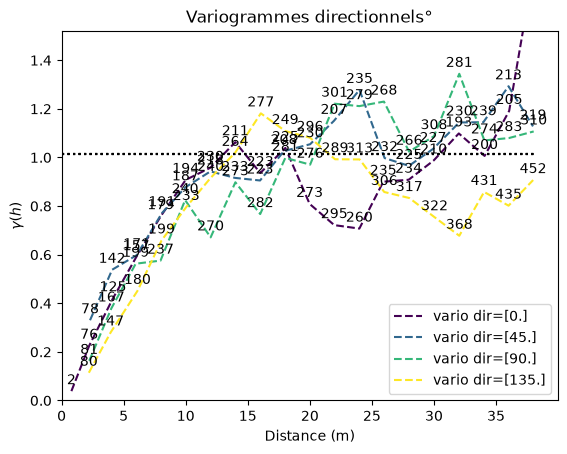

In [92]:
number_of_lags = 20
lag_distance = 2
azimut_main = None
azimut_min = None

params_vario_dir = gl.VarioParam.createMultiple(ndir=4, nlag=number_of_lags, dlag=lag_distance)

for direction in (azimut_min, azimut_main):
    if direction:
        dir_main = gl.DirParam.create(nlag=number_of_lags, dlag=lag_distance,
                                      tolang=15, cylrad=5, angle2D = 90 - direction)
        params_vario_dir.addDir(dir_main)

variogram_dir = gl.Vario(params_vario_dir)
variogram_dir.compute(db)

ax = gp.varmod(variogram_dir, showPairs= True, flagLegend=True)
ax.set_ylim(0, variogram_dir.getVar() * 1.5)
plt.xlabel("Distance (m)")
plt.ylabel(r"$\gamma(h)$")
plt.title(f"Variogrammes directionnels°")
plt.show()

**Ces variogrammes sont-ils comparables à ceux de l'image entière ([Voir le notebook précédent](02_variogramme2D.ipynb)) ?**

Ici, le relativement faible nombre de points et la représentativité des échantillons rendent les calculs moins robustes.
Pour comprendre le problème, nous pouvons aussi calculer la carte variographique. Le paramètre `nxx`est important car il contrôle la résolution de cette carte (et donc les tolérances)

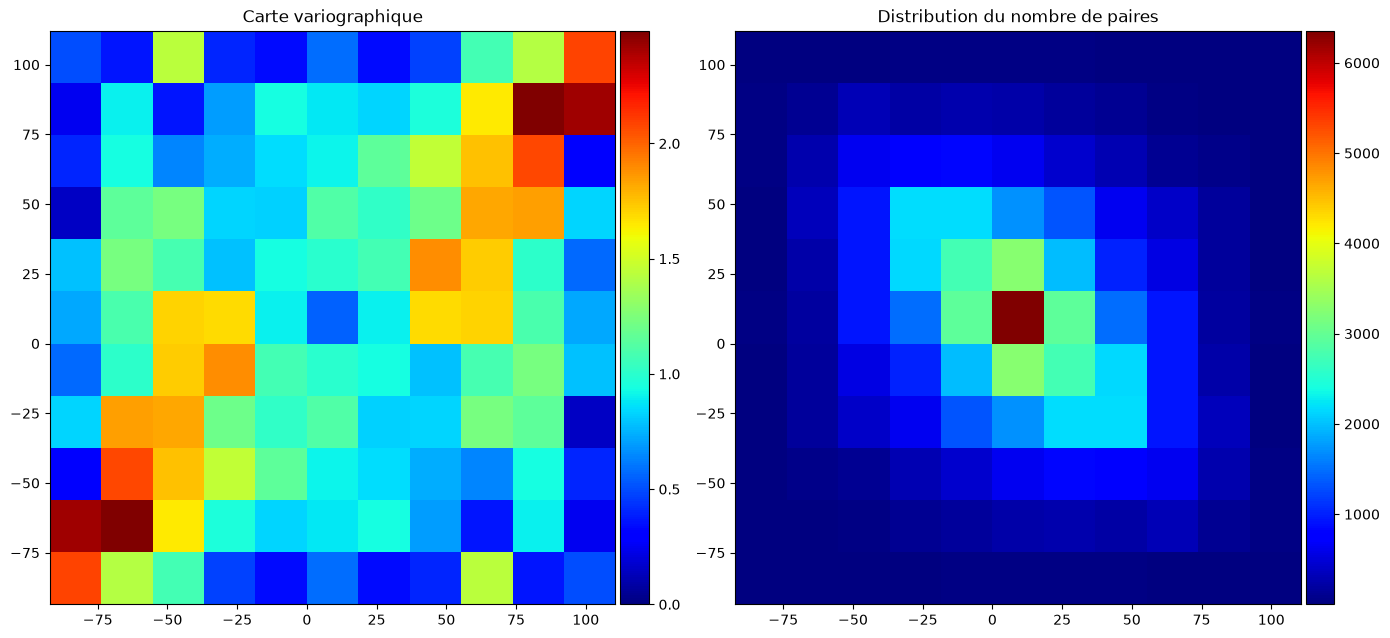

In [94]:
variogram_map = gl.db_vmap(db, nxx=[5, 5])
fig, ax = gp.init(1, 2, figsize=(14, 7), flagEqual=True)
ax[0].raster(variogram_map, flagLegend=True, cmap="jet", vmin=0)
ax[0].decoration(title="Carte variographique")

#-----carte du nombre de paires -----
ax[1].raster(variogram_map, name="VMAP.Values.Nb", flagLegend=True, cmap="jet")
ax[1].decoration(title="Distribution du nombre de paires")
plt.tight_layout()
plt.show()

## 4. Calage du modèle de variogramme

Essayons maintenant de caler automatiquement un modèle de variogramme exponentiel et affichons-le


Model characteristics
Space dimension              = 2
Number of variable(s)        = 1
Number of basic structure(s) = 1
Number of drift function(s)  = 0
Number of drift equation(s)  = 0

Covariance Part
---------------
Exponential
- Sill         =       1.107
- Ranges       =     106.149     16.178
- Theo. Ranges =      35.433      5.401
- Angles       =     150.153      0.000
- Rotation Matrix
                 [,  0]     [,  1]
      [  0,]      0.867      0.498
      [  1,]     -0.498      0.867
Total Sill     =       1.107
Known Mean(s)      0.000



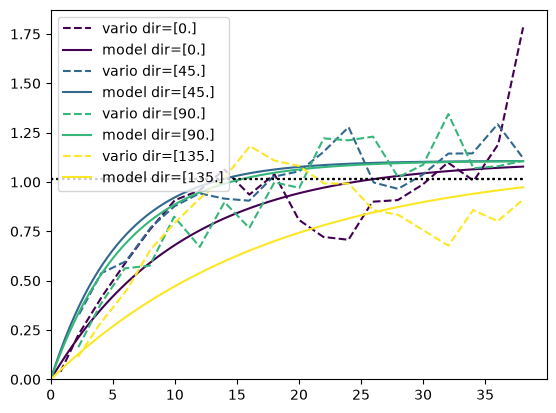

In [105]:
variogram_types = [gl.ECov.EXPONENTIAL]
variogram_model_all_directions = gl.Model()
variogram_model_all_directions.fitFromVMap(variogram_map, types=variogram_types)
print(variogram_model_all_directions)

ax = gp.varmod(variogram_dir, variogram_model_all_directions, flagLegend=True)

# interactive_fit = gsutils.InteractiveVariogramFit(variogram_dir, "m")
# interactive_fit.interact()
# fitted_vario_model = interactive_fit.model
# print(fitted_vario_model)

## 5. Estimation par Krigeage

Grâce à notre modèle de variogramme, nous pouvons désormais réaliser un krigeage pour estimer les valeurs entre les points. POur cela, nous allons travailler sur la grille de référence.

In [108]:
estimation_grid = gsutils.creer_grille(data_2d, nx=100, ny=100)
print(estimation_grid)

gsutils.krigeage_sk_ok_uk(
    dbin=db, dbout=estimation_grid,
    model_base=variogram_model_all_directions, nom_variable="Values"
)
gsutils.creer_widget_cartes_krigeage(
    dbout=db, dbin=estimation_grid,
    nom_variable="Values", cmap="PiYG"
)


Data Base Grid Characteristics

Data Base Summary
-----------------
File is organized as a regular grid
Space dimension              = 2
Number of Columns            = 3
Total number of samples      = 10000

Grid characteristics:
---------------------
Origin :       3.732      2.270
Mesh   :       0.922      0.935
Number :         100        100

Variables
---------
Column = 0 - Name = rank - Locator = NA
Column = 1 - Name = x1 - Locator = x1
Column = 2 - Name = x2 - Locator = x2



## 11. Simulation par bandes tournantes (TBS)

In [ ]:
prefixe_gold = gsutils.simulation_bandes_tournantes(
    dbin=db_gold2d, dbout=grid_gold,
    model_base=model_final_gold2d, nom_variable="Values"
)
gsutils.creer_widget_realisations(
    dbout=grid_gold, dbin=db_gold2d,
    prefixe=prefixe_gold, nom_variable="Values", cmap="PiYG"
)